# Лабораторна робота 2_1
## Обробка та аналіз даних про ВВП

Показники з таблиці [Wikipedia](https://en.wikipedia.org/wiki/List_of_countries_by_GDP_(nominal)), знімок від 17.11.2026. Одиниця вимірювання: мільйон доларів США. Заголовки джерела відповідають IMF 2026, World Bank 2025 та United Nations 2024. Це різні джерела оцінок, а не узгоджена панель щорічних спостережень; окремі рядки можуть мати примітки про інший рік.

1. Вивести перші 5 рядків датасета

In [1]:
from pathlib import Path
from io import StringIO
import re
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display,Markdown

In [2]:
url='https://en.wikipedia.org/wiki/List_of_countries_by_GDP_(nominal)'
file=Path('gdp.html')
if not file.exists():file=Path('Джерельні файли')/file
if file.exists():html=file.read_text(encoding='utf-8')
else:
    response=requests.get(url,headers={'User-Agent':'Mozilla/5.0'},timeout=60)
    response.raise_for_status()
    html=response.text
tables=pd.read_html(StringIO(html))
df=next(t for t in tables if 'Country/Territory' in t.columns and any('United Nations' in str(c) for c in t.columns)).copy()
display(df.head())
print('Заголовки джерела:',list(df.columns))

,Country/Territory,IMF (2026)[1],World Bank (2025)[6],United Nations (2024)[7]
0,World,128003776,118350166,111565144
1,United States,32642373,30769700,29298000
2,China[n 1],21546403,19498039,18743802
3,Germany,5471299,5050923,4659929
4,Japan,4341986,4435163,4026211


Заголовки джерела: ['Country/Territory', 'IMF (2026)[1]', 'World Bank (2025)[6]', 'United Nations (2024)[7]']


2.	Визначити розмір датасета.

In [3]:
print('Початковий розмір:',df.shape)

Початковий розмір: (222, 4)


 3.	Визначити оптимальну кількість стовпців (видалити зайві, на власний розсуд).

In [4]:
df=df.iloc[:,:4].copy()
df.columns=['Країна','IMF 2026','World Bank 2025','UN 2024']
df['Країна']=df['Країна'].astype(str).str.replace(r'\[.*?\]','',regex=True).str.strip()
df=df.loc[df['Країна']!='World'].copy()
value_cols=['IMF 2026','World Bank 2025','UN 2024']
print('Залишено назву та три оцінки ВВП. Світовий підсумок вилучено для уникнення подвійного підрахунку.')
print(df.shape)

Залишено назву та три оцінки ВВП. Світовий підсумок вилучено для уникнення подвійного підрахунку.
(221, 4)


4.	Замініть у таблиці значення ":" на значення NaN. Перевірити наявність пропущених значень. При наявності, замінити пропущені значення на середнє значення.

In [5]:
for col in value_cols:
    values=df[col].astype(str).str.replace(r'\[.*?\]','',regex=True).str.replace(',','',regex=False)
    values=values.str.replace(r'\s+','',regex=True).replace({'—':np.nan,'–':np.nan,'-':np.nan})
    df[col]=pd.to_numeric(values,errors='coerce')
missing_before=df[value_cols].isna().sum()
display(missing_before)
observed=df.copy()

IMF 2026           30
World Bank 2025    35
UN 2024             9
dtype: int64

In [6]:
df[value_cols]=df[value_cols].fillna(df[value_cols].mean())
display(df.isna().sum())

Країна             0
IMF 2026           0
World Bank 2025    0
UN 2024            0
dtype: int64

5. Ще раз вивести датасет

In [7]:
display(df)

,Країна,IMF 2026,World Bank 2025,UN 2024
1,United States,3.264237e+07,3.076970e+07,29298000.0
2,China,2.154640e+07,1.949804e+07,18743802.0
3,Germany,5.471299e+06,5.050923e+06,4659929.0
4,Japan,4.341986e+06,4.435163e+06,4026211.0
5,United Kingdom,4.268446e+06,4.002588e+06,3685881.0
...,...,...,...,...
217,Palau,3.770000e+02,3.450000e+02,310.0
218,Marshall Islands,3.420000e+02,3.080000e+02,281.0
219,Nauru,1.960000e+02,1.760000e+02,187.0
220,Montserrat,6.690289e+05,6.260497e+05,81.0


6.	Перевірити наявність дублікатів. При наявності видалити дублікати.

In [8]:
print('Дублікати:',df.duplicated().sum())
df=df.drop_duplicates().reset_index(drop=True)
print('Після видалення:',df.shape)

Дублікати: 0
Після видалення: (221, 4)


7.	Вивести описову статистику датасету describe()

In [9]:
display(df.describe())

,IMF 2026,World Bank 2025,UN 2024
count,2.210000e+02,2.210000e+02,2.210000e+02
mean,6.690289e+05,6.260497e+05,5.224912e+05
std,2.705629e+06,2.520399e+06,2.410079e+06
min,6.500000e+01,5.700000e+01,5.600000e+01
25%,1.895900e+04,1.992800e+04,8.840000e+03
50%,1.020420e+05,9.977400e+04,4.276500e+04
75%,6.690289e+05,6.260497e+05,2.986970e+05
max,3.264237e+07,3.076970e+07,2.929800e+07


8. Визначте відхилення (різницю) між показниками IMF (2026) та World Bank (2025) для кожної країни. У яких країнах ці показники найбільше відрізняються (дати відповідь)?

In [10]:
df['IMF мінус WB']=df['IMF 2026']-df['World Bank 2025']
difference=df[['Країна','IMF мінус WB']].assign(Абсолютна_різниця=lambda t:t['IMF мінус WB'].abs()).sort_values('Абсолютна_різниця',ascending=False)
display(difference.head(10))
print('Найбільші різниці:',', '.join(difference['Країна'].head(3)))

,Країна,IMF мінус WB,Абсолютна_різниця
1,China,2.048364e+06,2.048364e+06
0,United States,1.872673e+06,1.872673e+06
196,Sint Maarten,6.671409e+05,6.671409e+05
145,Palestine,6.518619e+05,6.518619e+05
191,San Marino,-6.236327e+05,6.236327e+05
178,Aruba,-6.213787e+05,6.213787e+05
171,South Sudan,-6.199807e+05,6.199807e+05
167,Yemen,-6.186147e+05,6.186147e+05
158,Liechtenstein,-6.166077e+05,6.166077e+05
147,Bahamas,-6.090077e+05,6.090077e+05


Найбільші різниці: China, United States, Sint Maarten


9.	Обчисліть кореляцію між показниками IMF (2026), World Bank (2025) та United Nations (2024). Які пари змінних мають найвищу кореляцію?

In [11]:
corr=df[value_cols].corr()
display(corr)
pairs=corr.where(np.triu(np.ones(corr.shape),1).astype(bool)).stack()
print('Найвища кореляція:',pairs.idxmax(),'=',pairs.max())

,IMF 2026,World Bank 2025,UN 2024
IMF 2026,1.000000,0.998462,0.997189
World Bank 2025,0.998462,1.000000,0.997011
UN 2024,0.997189,0.997011,1.000000


Найвища кореляція: ('IMF 2026', 'World Bank 2025') = 0.9984619986664564


Обчислити середнє значення за стовпцями

In [12]:
display(df[value_cols].mean().rename('Середній ВВП'))

IMF 2026           669028.937173
World Bank 2025    626049.693548
UN 2024            522491.207547
Name: Середній ВВП, dtype: float64

11.	Обчисліть стандартне відхилення показників для кожної країни. Яка країна має найвищу варіативність у показниках між роками?

In [13]:
df['Стандартне відхилення']=df[value_cols].std(axis=1)
variability=df[['Країна','Стандартне відхилення']].sort_values('Стандартне відхилення',ascending=False)
display(variability.head(10))
print('Найвища варіативність:',variability.iloc[0]['Країна'])

,Країна,Стандартне відхилення
0,United States,1.676188e+06
1,China,1.450244e+06
2,Germany,4.057737e+05
196,Sint Maarten,3.852369e+05
145,Palestine,3.766851e+05
219,Montserrat,3.744274e+05
214,Cook Islands,3.742355e+05
213,Anguilla,3.742113e+05
200,Turks and Caicos Islands,3.734614e+05
198,British Virgin Islands,3.734193e+05


Найвища варіативність: United States


12.	Визначення країни з найвищим та найнижчим показниками: Знайдіть країну з найвищим та найнижчим показниками у кожному з років (IMF (2026), World Bank (2025), United Nations (2024)).

In [14]:
extremes=[]
for col in value_cols:
    for label,index in [('Максимум',df[col].idxmax()),('Мінімум',df[col].idxmin())]:
        extremes.append({'Джерело':col,'Показник':label,'Країна':df.loc[index,'Країна'],'ВВП':df.loc[index,col]})
display(pd.DataFrame(extremes))

,Джерело,Показник,Країна,ВВП
0,IMF 2026,Максимум,United States,32642373.0
1,IMF 2026,Мінімум,Tuvalu,65.0
2,World Bank 2025,Максимум,United States,30769700.0
3,World Bank 2025,Мінімум,Tuvalu,57.0
4,UN 2024,Максимум,United States,29298000.0
5,UN 2024,Мінімум,Tuvalu,56.0


13.	Побудуйте гістограму для розподілу показників IMF (2026) серед всіх країн. Який вигляд має розподіл? Чи є країни, що виділяються?

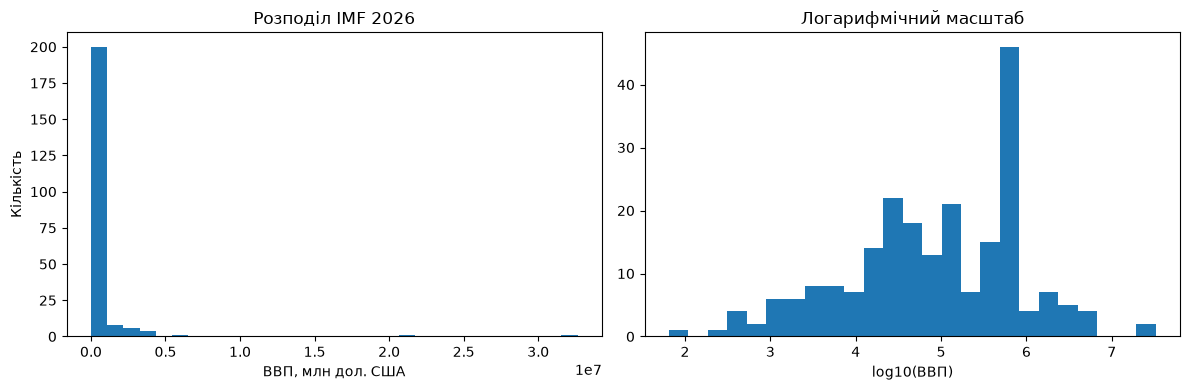

Розподіл має довгий правий хвіст. Найбільші значення: United States, China, Germany


In [15]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].hist(df['IMF 2026'],bins=30)
axes[0].set(title='Розподіл IMF 2026',xlabel='ВВП, млн дол. США',ylabel='Кількість')
axes[1].hist(np.log10(df.loc[df['IMF 2026']>0,'IMF 2026']),bins=25)
axes[1].set(title='Логарифмічний масштаб',xlabel='log10(ВВП)')
plt.tight_layout()
plt.show()
print('Розподіл має довгий правий хвіст. Найбільші значення:',', '.join(df.nlargest(3,'IMF 2026')['Країна']))

14.	Розрахуйте частку кожної країни в загальному значенні для кожного року (IMF (2026), World Bank (2025), United Nations (2024)).
 Як змінюються частки країн з часом (дати відповідь)?

In [16]:
shares=df.set_index('Країна')[value_cols].div(df[value_cols].sum(),axis=1)*100
display(shares)
top=df.nlargest(10,'IMF 2026')['Країна']
display(shares.loc[top])
print('Суми часток:',shares.sum().round(6).to_dict())

,IMF 2026,World Bank 2025,UN 2024
Країна,,,
United States,22.077228,22.239355,25.372702
China,14.572619,14.092559,16.232538
Germany,3.700439,3.650646,4.035599
Japan,2.936644,3.205594,3.486786
United Kingdom,2.886906,2.892943,3.192053
...,...,...,...
Palau,0.000255,0.000249,0.000268
Marshall Islands,0.000231,0.000223,0.000243
Nauru,0.000133,0.000127,0.000162


,IMF 2026,World Bank 2025,UN 2024
Країна,,,
United States,22.077228,22.239355,25.372702
China,14.572619,14.092559,16.232538
Germany,3.700439,3.650646,4.035599
Japan,2.936644,3.205594,3.486786
United Kingdom,2.886906,2.892943,3.192053
India,2.746066,2.859319,3.422729
France,2.403805,2.433065,2.737012
Russia,1.935104,1.851233,1.882199
Italy,1.827283,1.844184,2.061846


Суми часток: {'IMF 2026': 100.0, 'World Bank 2025': 100.0, 'UN 2024': 100.0}


15.	Візуалізуйте зміни в показниках для кожної країни за три роки на графіку. Які країни показують стабільне зростання або спад (дати відповідь)?

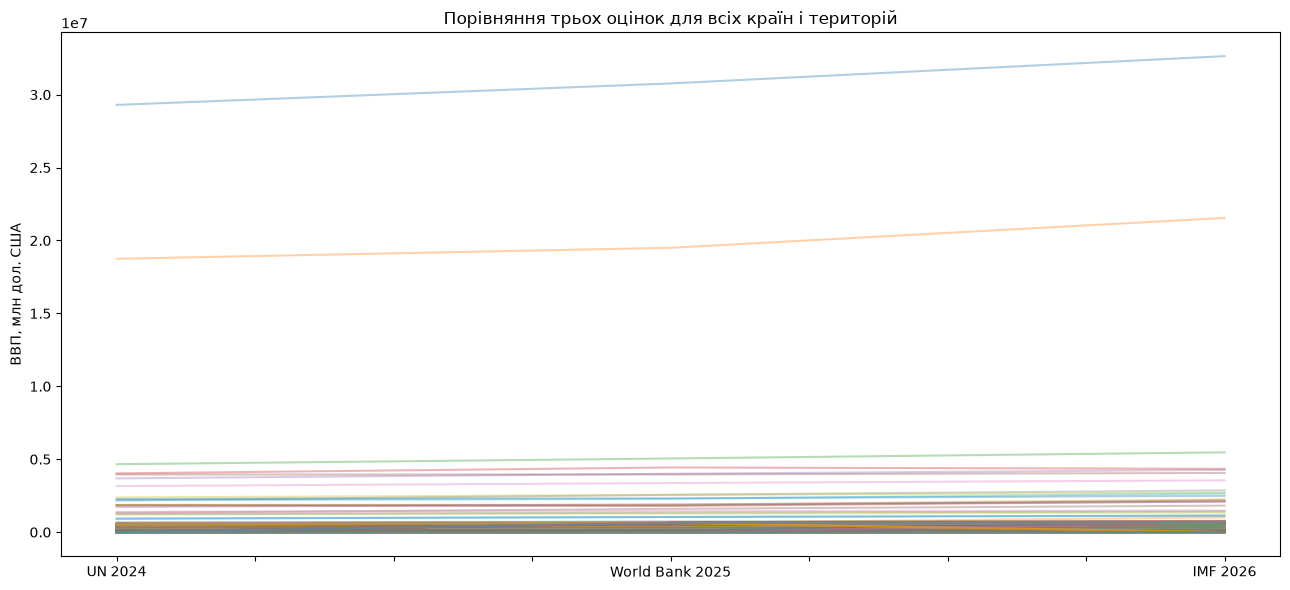

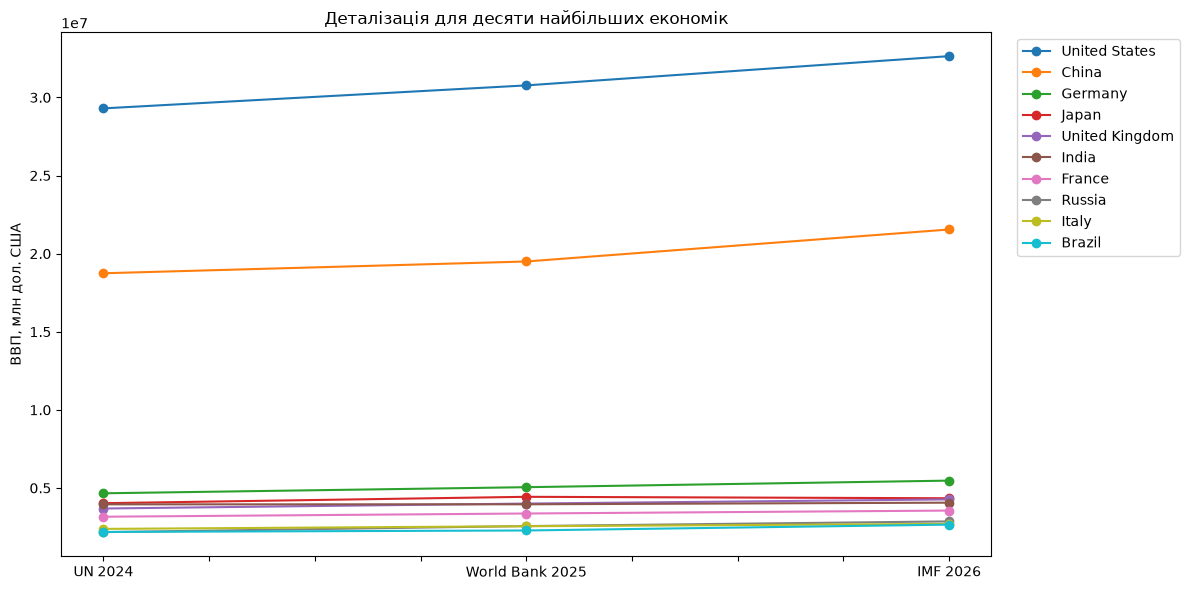

Послідовно більші оцінки: United States, China, Germany, United Kingdom, India, France, Russia, Italy, Brazil, Canada, Spain, Turkey, Indonesia, Netherlands, Saudi Arabia, Switzerland, Poland, Taiwan, Belgium, Argentina, Israel, Sweden, Singapore, United Arab Emirates, Norway, Austria, Thailand, Colombia, Malaysia, Vietnam, Bangladesh, Philippines, Denmark, South Africa, Romania, Hong Kong, Pakistan, Egypt, Czech Republic, Chile, Peru, Kazakhstan, Nigeria, Portugal, Finland, Algeria, Greece, New Zealand, Hungary, Cuba, Ukraine, Morocco, Uzbekistan, Slovakia, Angola, Kenya, Bulgaria, Dominican Republic, Ecuador, Puerto Rico, Guatemala, Ghana, DR Congo, Oman, Croatia, Ivory Coast, Serbia, Luxembourg, Costa Rica, Sri Lanka, Lithuania, Belarus, Uruguay, Panama, Tanzania, Slovenia, Myanmar, Bolivia, Azerbaijan, Uganda, Cameroon, Jordan, Tunisia, Paraguay, Zimbabwe, Macau, Latvia, Cambodia, Estonia, Nepal, Cyprus, Iceland, Georgia, Honduras, Zambia, Senegal, El Salvador, Haiti, Bosnia and He

In [17]:
order=['UN 2024','World Bank 2025','IMF 2026']
values=df.set_index('Країна')[order]
values.T.plot(figsize=(13,6),legend=False,alpha=0.35)
plt.ylabel('ВВП, млн дол. США')
plt.title('Порівняння трьох оцінок для всіх країн і територій')
plt.tight_layout()
plt.show()
values.loc[top].T.plot(figsize=(12,6),marker='o')
plt.ylabel('ВВП, млн дол. США')
plt.title('Деталізація для десяти найбільших економік')
plt.legend(bbox_to_anchor=(1.02,1),loc='upper left')
plt.tight_layout()
plt.show()
increasing=values.index[(values.diff(axis=1).iloc[:,1:]>0).all(axis=1)].tolist()
decreasing=values.index[(values.diff(axis=1).iloc[:,1:]<0).all(axis=1)].tolist()
print('Послідовно більші оцінки:',', '.join(increasing))
print('Послідовно менші оцінки:',', '.join(decreasing) or 'немає')
share_delta=(shares['IMF 2026']-shares['UN 2024']).sort_values()
print('Найбільше збільшення частки, в.п.:',share_delta.tail(5).to_dict())
print('Найбільше зменшення частки, в.п.:',share_delta.head(5).to_dict())

## Висновок
Опрацьовано 221 країн і територій, світовий підсумок вилучено. Пропуски (74 значень) заповнено середніми відповідних стовпців за умовою; це може спотворювати порівняння малих економік і частки. Найбільша абсолютна різниця між IMF і World Bank спостерігається для China, а найбільше стандартне відхилення між трьома оцінками має United States. Найвища кореляція отримана між IMF 2026 та World Bank 2025: 0.9985. Розподіл ВВП правосторонньо асиметричний: небагато великих економік значно перевищують решту. Частки обчислено від суми представлених країн і територій після заповнення пропусків, тому це навчальна оцінка, а не офіційні світові частки. Зміни оцінок за 2024-2026 роки та перелік зростання/спаду наведено вище; через різні джерела, прогнози IMF та валютні курси вони не доводять відповідної зміни реального виробництва.